# Marketing KPI analysis with sample campaign data
This is a reproducible demonstration using three small tables created in Python, with four campaign records. It is not client data or a deployed production pipeline. Business question: how do campaign efficiency metrics differ within this illustrative example?


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
campaigns=pd.DataFrame({"campaign_id":[1,2,3,4],"campaign_name":["Spring Sale","Summer Promo","Holiday Deal","New Launch"],"impressions":[100000,80000,120000,60000],"clicks":[5000,3200,4800,1800]})
spend=pd.DataFrame({"campaign_id":[1,2,3,4],"spend":[2500,1800,3200,1500]})
conversions=pd.DataFrame({"campaign_id":[1,2,3,4],"conversions":[250,140,300,90],"revenue":[12500,7000,18000,6000]})
for frame in [campaigns,spend,conversions]:assert frame.campaign_id.is_unique
df=campaigns.merge(spend,on="campaign_id",validate="one_to_one").merge(conversions,on="campaign_id",validate="one_to_one")
assert df[["impressions","clicks","spend"]].gt(0).all().all()
df["CTR_pct"]=100*df.clicks/df.impressions
df["CPC"]=df.spend/df.clicks
df["conversion_rate_pct"]=100*df.conversions/df.clicks
df["CPA"]=df.spend/df.conversions
df["ROAS"]=df.revenue/df.spend
print(df.round(3).to_string(index=False))
print("Total spend:",df.spend.sum(),"Total revenue:",df.revenue.sum())
print("Overall ROAS (total revenue / total spend):",round(df.revenue.sum()/df.spend.sum(),3))
print("Unweighted mean campaign ROAS:",round(df.ROAS.mean(),3))


 campaign_id campaign_name  impressions  clicks  spend  conversions  revenue  CTR_pct   CPC  conversion_rate_pct    CPA  ROAS
           1   Spring Sale       100000    5000   2500          250    12500      5.0 0.500                5.000 10.000 5.000
           2  Summer Promo        80000    3200   1800          140     7000      4.0 0.562                4.375 12.857 3.889
           3  Holiday Deal       120000    4800   3200          300    18000      4.0 0.667                6.250 10.667 5.625
           4    New Launch        60000    1800   1500           90     6000      3.0 0.833                5.000 16.667 4.000
Total spend: 9000 Total revenue: 43500
Overall ROAS (total revenue / total spend): 4.833
Unweighted mean campaign ROAS: 4.628


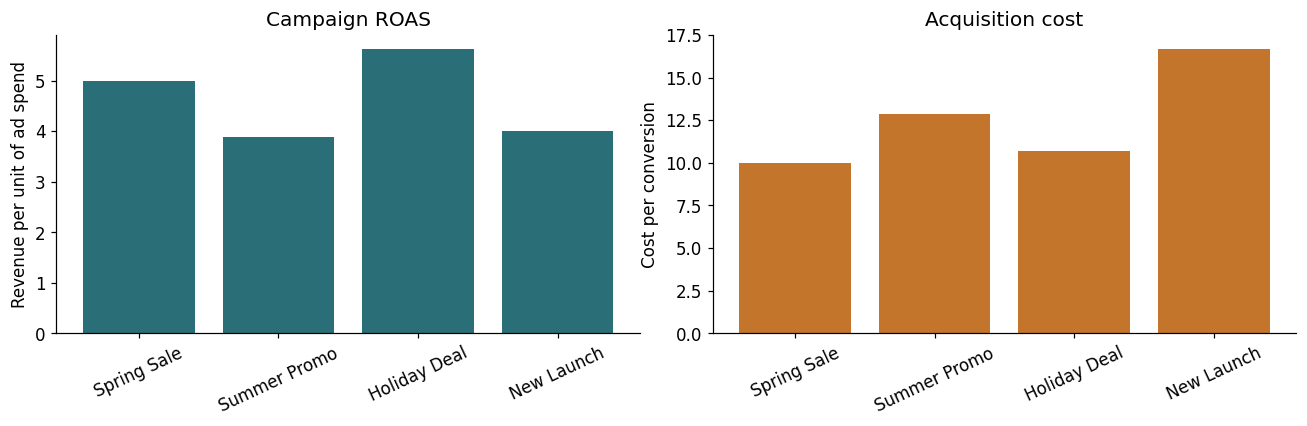

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(df.campaign_name,df.ROAS,color="#2A6F77");axes[0].set_ylabel("Revenue per unit of ad spend");axes[0].set_title("Campaign ROAS")
axes[1].bar(df.campaign_name,df.CPA,color="#C2752B");axes[1].set_ylabel("Cost per conversion");axes[1].set_title("Acquisition cost")
for ax in axes:ax.tick_params(axis="x",rotation=25)
plt.tight_layout();plt.show()


## Interpretation
In the sample, Holiday Deal has the highest ROAS (5.625), while Spring Sale has the lowest CPA (10). Overall ROAS is 4.833, distinct from the unweighted average of campaign ROAS (4.628). These are sample calculations, not evidence of real campaign performance. Revenue/spend is not profit ROI: margins, attribution, incremental effects and other costs are absent. Do not reallocate an actual budget from these example records.
